In [20]:
import os
import json
import cv2
import shutil
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

import random
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import ImageFolder

from transformers import (
    CLIPModel,
    CLIPProcessor
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

from transformers import (
    CLIPImageProcessor,
    CLIPVisionModelWithProjection
)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Device:", device)

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
Device: cuda


### Reproducibility

Set seed 42 and deterministic options where supported.

In [31]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print(f"Random seed set to {SEED}")


Random seed set to 42


## 1. Dataset Setup

Locate the preprocessed LAV-DF frame dataset and confirm the TRAIN/VAL folders.

In [22]:
for root, dirs, files in os.walk("/kaggle/input"):
    if "frames.csv" in files:
        print("Found:", root)
        print("Contents:", os.listdir(root))

Found: /kaggle/input/datasets/yanhanr/lav-df-frame
Contents: ['frames.csv', 'train', 'val']


In [23]:
DATA_ROOT = "/kaggle/input/datasets/yanhanr/lav-df-frame"

for split in ["train", "val"]:
    for label in ["fake", "real"]:
        folder = os.path.join(DATA_ROOT, split, label)
        print(split, label, len(os.listdir(folder)))

train fake 6000
train real 6000
val fake 750
val real 750


In [24]:
MODEL_NAME = "openai/clip-vit-base-patch32"

image_processor = CLIPImageProcessor.from_pretrained(
    MODEL_NAME
)

vision_encoder = CLIPVisionModelWithProjection.from_pretrained(
    MODEL_NAME
)

print("CLIP loaded successfully.")
print("Embedding dimension:",
      vision_encoder.visual_projection.out_features)

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] CLIPVisionModelWithProjection LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0

CLIP loaded successfully.
Embedding dimension: 512


## 2. Data Loading

Apply CLIP image preprocessing and create TRAIN/VAL DataLoaders.

In [34]:
def clip_transform(image):
    pixel_values = image_processor(
        images=image,
        return_tensors="pt"
    )["pixel_values"]

    return pixel_values.squeeze(0)


train_dataset = ImageFolder(
    os.path.join(DATA_ROOT, "train"),
    transform=clip_transform
)

val_dataset = ImageFolder(
    os.path.join(DATA_ROOT, "val"),
    transform=clip_transform
)


train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Classes:", train_dataset.class_to_idx)
print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Classes: {'fake': 0, 'real': 1}
Train images: 12000
Validation images: 1500


## 3. CLIP Binary Classifier

Use CLIP ViT-B/32 image embeddings with a two-class classification head.

In [36]:
class CLIPBinaryClassifier(nn.Module):

    def __init__(self, encoder):
        super().__init__()

        self.encoder = encoder

        embedding_dim = (
            encoder.visual_projection.out_features
        )

        self.classifier = nn.Linear(
            embedding_dim,
            2
        )

    def forward(self, pixel_values):

        outputs = self.encoder(
            pixel_values=pixel_values
        )

        embeddings = outputs.image_embeds

        # CLIP normally uses normalized embeddings
        embeddings = embeddings / embeddings.norm(
            dim=-1,
            keepdim=True
        )

        logits = self.classifier(
            embeddings
        )

        return logits


model = CLIPBinaryClassifier(
    vision_encoder
)

model = model.to(device)

print(model.classifier)

Linear(in_features=512, out_features=2, bias=True)


In [14]:
# test with small batch

images, labels = next(
    iter(train_loader)
)

print("Before GPU:")
print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

images = images.to(device)
labels = labels.to(device)

model.eval()

with torch.no_grad():

    outputs = model(images)

print("\nAfter model:")
print("Output shape:", outputs.shape)

Before GPU:
Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])

After model:
Output shape: torch.Size([32, 2])


## 4. Baseline Fine-Tuning

Fine-tune the encoder and classification head; select the best checkpoint using frame-level validation ROC-AUC.

In [37]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    [
        {
            "params": model.encoder.parameters(),
            "lr": 1e-5
        },
        {
            "params": model.classifier.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

MAX_EPOCHS = 15
PATIENCE = 5

BEST_MODEL_PATH = "/kaggle/working/clip_vit_b32_best.pt"

best_auc = -1.0
epochs_without_improvement = 0

history = []

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

for epoch in range(1, MAX_EPOCHS + 1):

    # =========================
    # Training
    # =========================
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        with torch.amp.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        # Helps prevent unstable large gradients
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        train_loss += (
            loss.item() * images.size(0)
        )

        predictions = outputs.argmax(dim=1)

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += labels.size(0)

    train_loss /= train_total
    train_accuracy = train_correct / train_total


    # =========================
    # Validation
    # =========================
    model.eval()

    val_loss = 0.0

    all_labels = []
    all_predictions = []
    all_fake_probs = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            with torch.amp.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda")
            ):
                outputs = model(images)
                loss = criterion(
                    outputs,
                    labels
                )

            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            predictions = outputs.argmax(
                dim=1
            )

            val_loss += (
                loss.item() * images.size(0)
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            # ImageFolder:
            # fake = 0
            all_fake_probs.extend(
                probabilities[:, 0]
                .cpu()
                .numpy()
            )

    val_loss /= len(val_dataset)

    all_labels = np.array(all_labels)
    all_predictions = np.array(
        all_predictions
    )
    all_fake_probs = np.array(
        all_fake_probs
    )

    # Convert:
    # Real = 0
    # Fake = 1
    y_true_fake = (
        all_labels == 0
    ).astype(int)

    y_pred_fake = (
        all_predictions == 0
    ).astype(int)

    val_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    val_precision = precision_score(
        y_true_fake,
        y_pred_fake
    )

    val_recall = recall_score(
        y_true_fake,
        y_pred_fake
    )

    val_f1 = f1_score(
        y_true_fake,
        y_pred_fake
    )

    val_auc = roc_auc_score(
        y_true_fake,
        all_fake_probs
    )


    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_precision": val_precision,
        "val_recall": val_recall,
        "val_f1": val_f1,
        "val_auc": val_auc
    })


    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"Val AUC: {val_auc:.4f}"
    )


    # =========================
    # Save best model
    # =========================
    if val_auc > best_auc:

        best_auc = val_auc
        epochs_without_improvement = 0

        torch.save({
            "epoch": int(epoch),
            "model_state_dict": model.state_dict(),
            "val_auc": float(val_auc),
            "class_to_idx": train_dataset.class_to_idx,
            "model_name": MODEL_NAME
        }, BEST_MODEL_PATH)

        print("  → Best model saved")

    else:

        epochs_without_improvement += 1


    # =========================
    # Early stopping
    # =========================
    if epochs_without_improvement >= PATIENCE:

        print(
            f"\nEarly stopping after "
            f"{epoch} epochs."
        )

        break


history_df = pd.DataFrame(history)

history_df.to_csv(
    "/kaggle/working/"
    "clip_training_history.csv",
    index=False
)

print("\nTraining finished.")
print(
    "Best validation ROC-AUC:",
    round(best_auc, 4)
)
print(
    "Best checkpoint:",
    BEST_MODEL_PATH
)

Epoch 01 | Train Loss: 0.4118 | Train Acc: 0.8984 | Val Loss: 0.4195 | Val Acc: 0.8547 | Val F1: 0.8595 | Val AUC: 0.9284
  → Best model saved
Epoch 02 | Train Loss: 0.3108 | Train Acc: 0.9173 | Val Loss: 0.3988 | Val Acc: 0.8580 | Val F1: 0.8464 | Val AUC: 0.9140
Epoch 03 | Train Loss: 0.2438 | Train Acc: 0.9335 | Val Loss: 0.3907 | Val Acc: 0.8567 | Val F1: 0.8472 | Val AUC: 0.9361
  → Best model saved
Epoch 04 | Train Loss: 0.1823 | Train Acc: 0.9523 | Val Loss: 0.4605 | Val Acc: 0.8307 | Val F1: 0.8403 | Val AUC: 0.9224
Epoch 05 | Train Loss: 0.1609 | Train Acc: 0.9544 | Val Loss: 0.5716 | Val Acc: 0.8133 | Val F1: 0.7816 | Val AUC: 0.9179
Epoch 06 | Train Loss: 0.1308 | Train Acc: 0.9657 | Val Loss: 0.4343 | Val Acc: 0.8707 | Val F1: 0.8693 | Val AUC: 0.9342
Epoch 07 | Train Loss: 0.1082 | Train Acc: 0.9724 | Val Loss: 0.6402 | Val Acc: 0.8260 | Val F1: 0.8390 | Val AUC: 0.9177
Epoch 08 | Train Loss: 0.0921 | Train Acc: 0.9775 | Val Loss: 0.5343 | Val Acc: 0.8633 | Val F1: 0.8627 

### 4.1 Best Checkpoint

Restore the checkpoint selected on validation ROC-AUC.

In [38]:
BEST_MODEL_PATH = "/kaggle/working/clip_vit_b32_best.pt"

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(device)
model.eval()

print("Best epoch:", checkpoint["epoch"])
print("Best validation AUC:", checkpoint["val_auc"])
print("Classes:", checkpoint["class_to_idx"])
print("Model:", checkpoint["model_name"])
print("Best CLIP model loaded successfully.")

Best epoch: 3
Best validation AUC: 0.9360702222222222
Classes: {'fake': 0, 'real': 1}
Model: openai/clip-vit-base-patch32
Best CLIP model loaded successfully.


In [39]:
checkpoint_path = Path("/kaggle/working/clip_vit_b32_best.pt")

assert checkpoint_path.exists(), "Checkpoint not found!"

print("Checkpoint found!")
print("Path:", checkpoint_path)
print(
    "Size:",
    round(checkpoint_path.stat().st_size / 1024**2, 2),
    "MB"
)


Checkpoint found!
Path: /kaggle/working/clip_vit_b32_best.pt
Size: 335.2 MB


In [40]:
checkpoint = torch.load(
    "/kaggle/working/clip_vit_b32_best.pt",
    map_location="cpu",
    weights_only=False
)

print("Checkpoint loaded successfully!")
print("Saved epoch:", checkpoint.get("epoch"))
print("Saved validation AUC:", checkpoint.get("val_auc"))
print("Model weights saved:",
      "model_state_dict" in checkpoint)

Checkpoint loaded successfully!
Saved epoch: 3
Saved validation AUC: 0.9360702222222222
Model weights saved: True


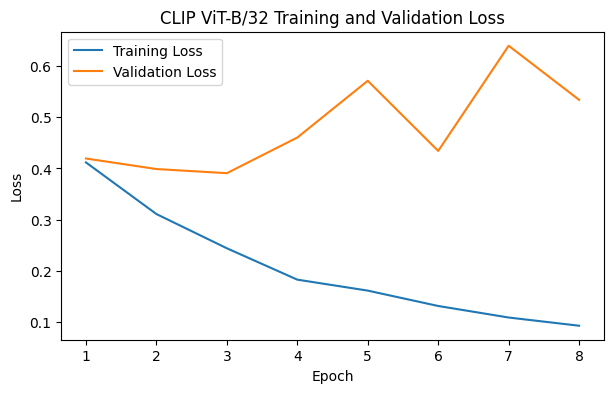

In [41]:
# loss
plt.figure(figsize=(7, 4))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Training Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CLIP ViT-B/32 Training and Validation Loss")
plt.legend()
plt.show()

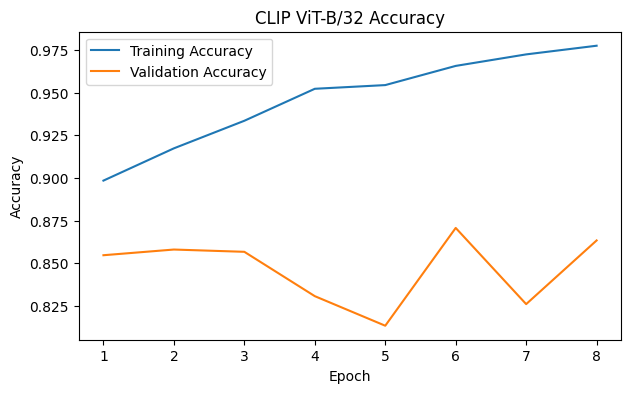

In [42]:
plt.figure(figsize=(7, 4))

plt.plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CLIP ViT-B/32 Accuracy")
plt.legend()
plt.show()

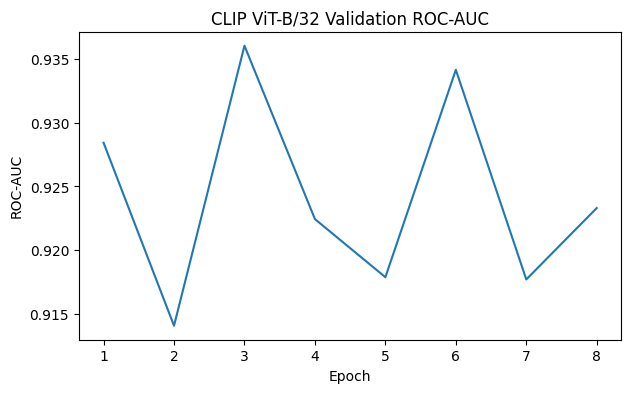

In [43]:
plt.figure(figsize=(7, 4))

plt.plot(
    history_df["epoch"],
    history_df["val_auc"]
)

plt.xlabel("Epoch")
plt.ylabel("ROC-AUC")
plt.title("CLIP ViT-B/32 Validation ROC-AUC")
plt.show()

### 4.2 Training Curves

Training and validation diverge in later epochs, indicating overfitting. Best checkpoint: epoch 3. See the README for analysis.

## 5. Original Whole-Video DEV Evaluation

Evaluate the baseline on 500 DEV videos using 16 uniformly sampled frames per video; frame selection does not use fake-period annotations.

In [44]:
# Load original LAV-DF metadata for DEV evaluation

# Find the original LAV-DF dataset
dev_metadata_candidates = []

for root, dirs, files in os.walk("/kaggle/input"):
    if "metadata.min.json" in files:
        dev_metadata_candidates.append(Path(root))

print("Metadata candidates:")
for path in dev_metadata_candidates:
    print(path)

assert len(dev_metadata_candidates) == 1, (
    "Expected exactly one metadata.min.json. "
    "Please verify the original dataset path."
)

DEV_ORIGINAL_ROOT = dev_metadata_candidates[0]
DEV_METADATA_PATH = (
    DEV_ORIGINAL_ROOT / "metadata.min.json"
)

with open(DEV_METADATA_PATH, "r") as f:
    dev_metadata = json.load(f)

dev_video_items = [
    item for item in dev_metadata
    if item["split"] == "dev"
]

print("\nOriginal dataset:", DEV_ORIGINAL_ROOT)
print("DEV videos:", len(dev_video_items))

print("\nVisual label distribution:")
print(
    pd.Series([
        int(item["modify_video"])
        for item in dev_video_items
    ]).value_counts().sort_index()
)

assert len(dev_video_items) == 500, (
    "Expected 500 DEV videos."
)


Metadata candidates:
/kaggle/input/datasets/yanhanr/lav-df-5000/LAV-DF-5000

Original dataset: /kaggle/input/datasets/yanhanr/lav-df-5000/LAV-DF-5000
DEV videos: 500

Visual label distribution:
0    250
1    250
Name: count, dtype: int64


### 5.1 Uniform DEV Sampling

Sample 16 frames across each DEV video.

In [45]:
# DEV video sampling and CLIP prediction functions

DEV_FRAMES_PER_VIDEO = 16

def dev_sample_video_frames(video_path, n_frames=16):

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        return []

    total_frames = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )

    if total_frames <= 0:
        cap.release()
        return []

    frame_indices = np.linspace(
        0,
        total_frames - 1,
        n_frames + 2,
        dtype=int
    )[1:-1]

    frames = []

    for frame_idx in frame_indices:

        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            int(frame_idx)
        )

        success, frame = cap.read()

        if success:
            frame = cv2.cvtColor(
                frame,
                cv2.COLOR_BGR2RGB
            )
            frames.append(Image.fromarray(frame))

    cap.release()

    return frames


def dev_predict_video_fake_probs(frames):

    if len(frames) == 0:
        return []

    tensors = [
        clip_transform(frame)
        for frame in frames
    ]

    batch = torch.stack(tensors).to(device)

    model.eval()

    with torch.no_grad():

        with torch.amp.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            outputs = model(batch)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        # ImageFolder mapping: fake = 0, real = 1
        fake_probs = (
            probabilities[:, 0]
            .cpu()
            .numpy()
        )

    return fake_probs


### 5.2 DEV Video Predictions

Generate and save per-frame fake scores for video-level aggregation.

In [46]:
# Generate CLIP predictions for all DEV videos

dev_video_records = []
dev_failed_videos = []

model.eval()

print(
    "Processing",
    len(dev_video_items),
    "DEV videos..."
)

for i, item in enumerate(dev_video_items, start=1):

    video_path = (
        DEV_ORIGINAL_ROOT / item["file"]
    )

    frames = dev_sample_video_frames(
        video_path,
        n_frames=DEV_FRAMES_PER_VIDEO
    )

    if len(frames) != DEV_FRAMES_PER_VIDEO:
        dev_failed_videos.append({
            "video": item["file"],
            "frames_read": len(frames)
        })
        continue

    fake_probs = dev_predict_video_fake_probs(frames)

    if len(fake_probs) != DEV_FRAMES_PER_VIDEO:
        dev_failed_videos.append({
            "video": item["file"],
            "frames_read": len(fake_probs)
        })
        continue

    dev_video_records.append({
        "video": item["file"],
        "true_label": int(item["modify_video"]),
        "num_frames": len(fake_probs),
        "max_prob": float(np.max(fake_probs)),
        "mean_prob": float(np.mean(fake_probs)),
        "frame_probs": json.dumps(
            [float(p) for p in fake_probs]
        )
    })

    if i % 100 == 0:
        print(
            f"Processed {i}/{len(dev_video_items)}"
        )

clip_dev_video_df = pd.DataFrame(dev_video_records)

print("\nDEV videos evaluated:", len(clip_dev_video_df))
print("Failed videos:", len(dev_failed_videos))

if dev_failed_videos:
    display(pd.DataFrame(dev_failed_videos))

assert len(dev_failed_videos) == 0, (
    "Some DEV videos could not be fully evaluated."
)

assert len(clip_dev_video_df) == 500

DEV_OUTPUT_DIR = Path("/kaggle/working")

clip_dev_video_df.to_csv(
    DEV_OUTPUT_DIR / "clip_video_dev_predictions.csv",
    index=False
)

display(clip_dev_video_df.head())

print("\nDEV predictions saved.")


Processing 500 DEV videos...
Processed 100/500
Processed 200/500
Processed 300/500
Processed 400/500
Processed 500/500

DEV videos evaluated: 500
Failed videos: 0


,video,true_label,num_frames,max_prob,mean_prob,frame_probs
0,dev/004173.mp4,0,16,0.848633,0.138062,"[0.09100341796875, 0.09063720703125, 0.0906372..."
1,dev/004174.mp4,1,16,0.899414,0.336670,"[0.87744140625, 0.87548828125, 0.8994140625, 0..."
2,dev/004175.mp4,1,16,0.902832,0.317139,"[0.8955078125, 0.90283203125, 0.8330078125, 0...."
3,dev/004176.mp4,0,16,0.899414,0.402100,"[0.8896484375, 0.5400390625, 0.09063720703125,..."
4,dev/004177.mp4,0,16,0.290771,0.115479,"[0.09063720703125, 0.090576171875, 0.090576171..."



DEV predictions saved.


### 5.3 Max-Pooling DEV Baseline

Aggregate by the maximum frame fake score; use threshold 0.5.

CLIP Whole-Video DEV Baseline

model: CLIP ViT-B/32
split: dev
aggregation: max
threshold: 0.5
frames_per_video: 16
accuracy: 0.746
precision: 0.7003257328990228
recall: 0.86
f1: 0.7719928186714542
roc_auc: 0.8488319999999999

Classification Report:
              precision    recall  f1-score   support

        Real       0.82      0.63      0.71       250
        Fake       0.70      0.86      0.77       250

    accuracy                           0.75       500
   macro avg       0.76      0.75      0.74       500
weighted avg       0.76      0.75      0.74       500



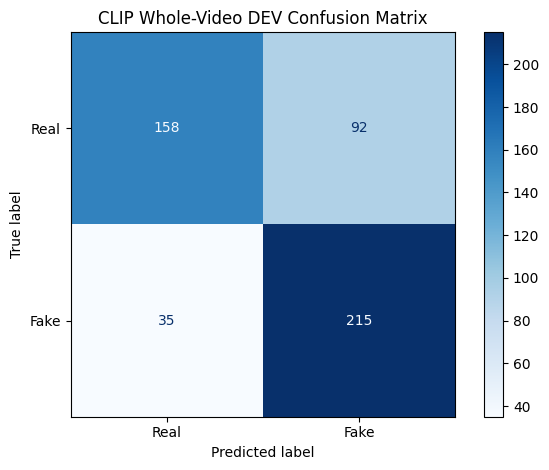

In [47]:
# Evaluate original max-pooling baseline on DEV

dev_y_true = clip_dev_video_df["true_label"].to_numpy()
dev_y_score = clip_dev_video_df["max_prob"].to_numpy()
dev_y_pred = (dev_y_score >= 0.5).astype(int)

dev_baseline_metrics = {
    "model": "CLIP ViT-B/32",
    "split": "dev",
    "aggregation": "max",
    "threshold": 0.5,
    "frames_per_video": DEV_FRAMES_PER_VIDEO,
    "accuracy": float(accuracy_score(dev_y_true, dev_y_pred)),
    "precision": float(precision_score(
        dev_y_true, dev_y_pred, zero_division=0
    )),
    "recall": float(recall_score(
        dev_y_true, dev_y_pred, zero_division=0
    )),
    "f1": float(f1_score(
        dev_y_true, dev_y_pred, zero_division=0
    )),
    "roc_auc": float(roc_auc_score(
        dev_y_true, dev_y_score
    ))
}

print("CLIP Whole-Video DEV Baseline\n")

for key, value in dev_baseline_metrics.items():
    print(f"{key}: {value}")

print("\nClassification Report:")
print(classification_report(
    dev_y_true,
    dev_y_pred,
    target_names=["Real", "Fake"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    dev_y_true,
    dev_y_pred,
    display_labels=["Real", "Fake"],
    cmap="Blues",
    values_format="d"
)

plt.title("CLIP Whole-Video DEV Confusion Matrix")
plt.tight_layout()
plt.savefig(
    "/kaggle/working/clip_video_dev_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

with open(
    "/kaggle/working/clip_video_dev_metrics.json", "w"
) as f:
    json.dump(dev_baseline_metrics, f, indent=4)


### 5.4 DEV Aggregation Comparison

Compare max, mean, top-3 mean and top-5 mean pooling on the same DEV predictions.

In [49]:
# Compare video aggregation methods on DEV

def aggregate_frame_scores(frame_probs, method):

    scores = np.asarray(frame_probs, dtype=float)

    if method == "max":
        return float(np.max(scores))

    if method == "mean":
        return float(np.mean(scores))

    if method == "top3":
        return float(np.mean(np.sort(scores)[-3:]))

    if method == "top5":
        return float(np.mean(np.sort(scores)[-5:]))

    raise ValueError(f"Unknown method: {method}")


aggregation_methods = ["max", "mean", "top3", "top5"]

# Decode the saved frame scores
dev_frame_scores = [
    json.loads(value)
    for value in clip_dev_video_df["frame_probs"]
]

aggregation_results = []

for method in aggregation_methods:

    scores = np.array([
        aggregate_frame_scores(probs, method)
        for probs in dev_frame_scores
    ])

    predictions = (scores >= 0.5).astype(int)

    aggregation_results.append({
        "method": method,
        "threshold": 0.5,
        "accuracy": accuracy_score(
            dev_y_true, predictions
        ),
        "precision": precision_score(
            dev_y_true, predictions, zero_division=0
        ),
        "recall": recall_score(
            dev_y_true, predictions, zero_division=0
        ),
        "f1": f1_score(
            dev_y_true, predictions, zero_division=0
        ),
        "roc_auc": roc_auc_score(
            dev_y_true, scores
        )
    })

aggregation_results_df = pd.DataFrame(
    aggregation_results
)

aggregation_results_df = (
    aggregation_results_df.sort_values(
        ["roc_auc", "f1"],
        ascending=False
    ).reset_index(drop=True)
)

display(aggregation_results_df.round(4))

aggregation_results_df.to_csv(
    "/kaggle/working/clip_dev_aggregation_comparison.csv",
    index=False
)


,method,threshold,accuracy,precision,recall,f1,roc_auc
0,max,0.5,0.746,0.7003,0.860,0.7720,0.8488
1,top3,0.5,0.672,0.7009,0.600,0.6466,0.7709
2,top5,0.5,0.618,0.6954,0.420,0.5237,0.7618
3,mean,0.5,0.522,0.6667,0.088,0.1555,0.7579


### 5.5 Aggregation Visualization

Plot DEV metrics for the candidate aggregation methods.

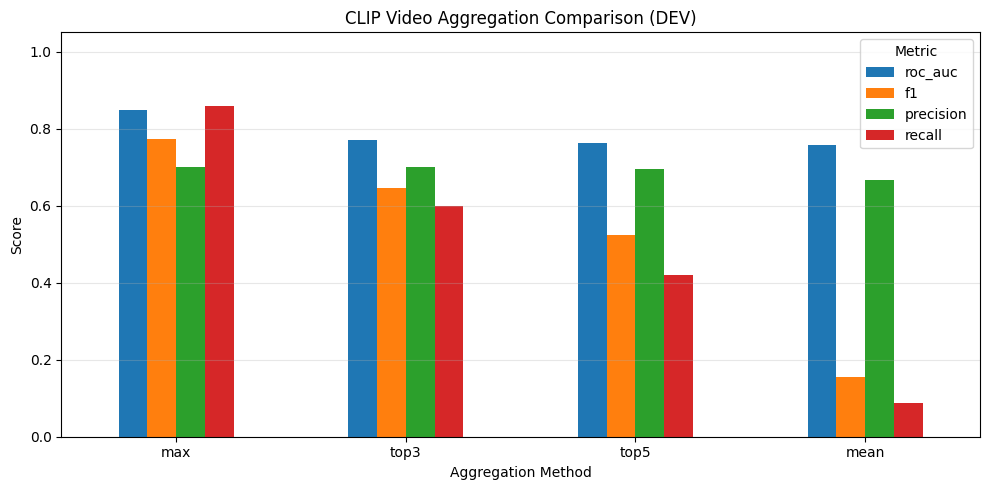

In [50]:
# Visualize DEV aggregation performance

plot_df = aggregation_results_df.set_index("method")

ax = plot_df[[
    "roc_auc", "f1", "precision", "recall"
]].plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

plt.title("CLIP Video Aggregation Comparison (DEV)")
plt.xlabel("Aggregation Method")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.legend(title="Metric")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/kaggle/working/clip_dev_aggregation_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


### 5.6 Aggregation Selection

Select the aggregation method using DEV ROC-AUC; max pooling was retained.

In [52]:
# Select aggregation method using DEV only

best_aggregation_row = aggregation_results_df.iloc[0]

SELECTED_AGGREGATION = str(
    best_aggregation_row["method"]
)

SELECTED_THRESHOLD = 0.5

selected_dev_config = {
    "model": "CLIP ViT-B/32",
    "selection_split": "dev",
    "aggregation": SELECTED_AGGREGATION,
    "threshold": SELECTED_THRESHOLD,
    "frames_per_video": DEV_FRAMES_PER_VIDEO,
    "selection_metric": "roc_auc",
    "dev_roc_auc": float(
        best_aggregation_row["roc_auc"]
    ),
    "dev_f1": float(
        best_aggregation_row["f1"]
    )
}

print("Selected aggregation:", SELECTED_AGGREGATION)
print("Selected threshold:", SELECTED_THRESHOLD)
print(
    "DEV ROC-AUC:",
    round(selected_dev_config["dev_roc_auc"], 4)
)
print(
    "DEV F1:",
    round(selected_dev_config["dev_f1"], 4)
)

with open(
    "/kaggle/working/clip_selected_dev_config.json", "w"
) as f:
    json.dump(selected_dev_config, f, indent=4)

print("\nSelected configuration saved.")


Selected aggregation: max
Selected threshold: 0.5
DEV ROC-AUC: 0.8488
DEV F1: 0.772

Selected configuration saved.


### 5.7 Baseline DEV Summary

Max pooling performed best among the tested aggregation rules. The baseline exhibited substantial false positives and motivated the frozen-encoder and lower-LR experiments in Notebook 04. Detailed results are in the README.